## HDBSCAN
### Clustering

In [1]:
#%reset -f 
%pip install nltk
import nltk
nltk.download('punkt')
nltk.download('wordnet')
%pip install WordCloud
%pip install hdbscan
#reset kernel
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from hdbscan import HDBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score, adjusted_mutual_info_score
from sklearn.model_selection import train_test_split

from wordcloud import WordCloud

Note: you may need to restart the kernel to use updated packages.


[nltk_data] Downloading package punkt to
[nltk_data]     /home/students/s346259/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/students/s346259/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


We could not execute HDBSCAN on the whole dataset due to memory constraint, therefore we used a subsample.
We considered using KMeans results

In [2]:
subsample_mask = np.load("subsample_mask.npy")

data = pd.read_csv(f"without_stopwords_150.csv")
data=data[subsample_mask]

#read npy file (pre-processing was done in 'unsupervised-pre-processing.ipynb')
X = np.load('X_reduced_150_lemmatizer_BoW.npy')
X=X[subsample_mask]

Testing with hyperparameters:  {'min_cluster_size': 6, 'min_samples': 6}
Cluster persistence: [0.00307351 0.00506428 0.00739815 0.3649576  0.62245302]


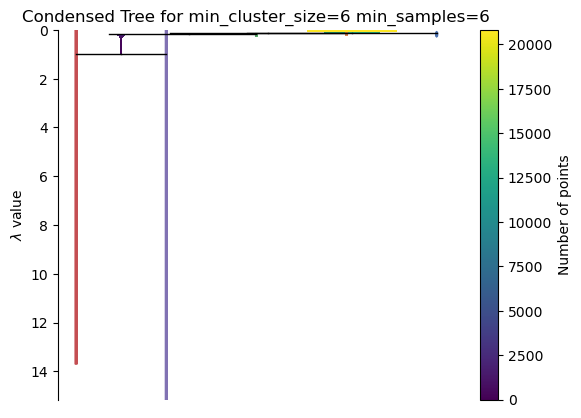

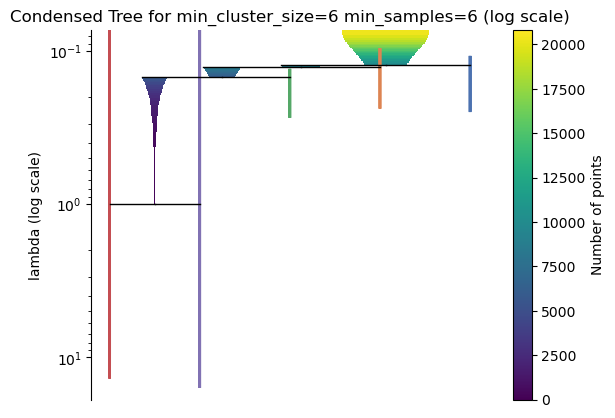

Silhouette Score (excluding outliers): 0.5218782628620313


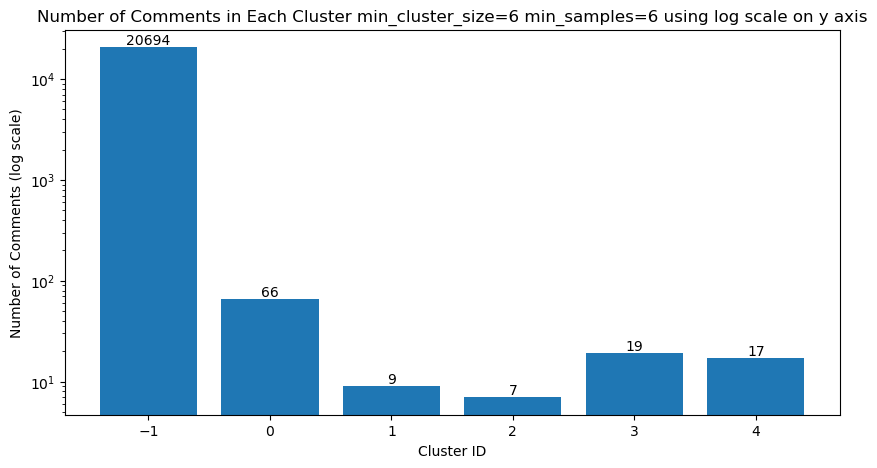

Cluster sizes:
 -1    20694
 0       66
 3       19
 4       17
 1        9
 2        7
Name: count, dtype: int64




Testing with hyperparameters:  {'min_cluster_size': 6, 'min_samples': 3}
Cluster persistence: [0.00186754 0.0033938  0.00492256 0.28730379 0.63978953]


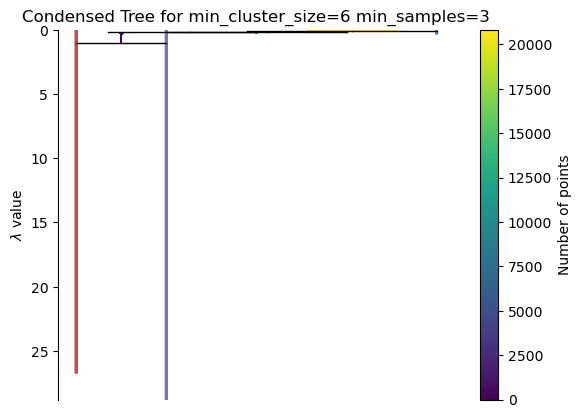

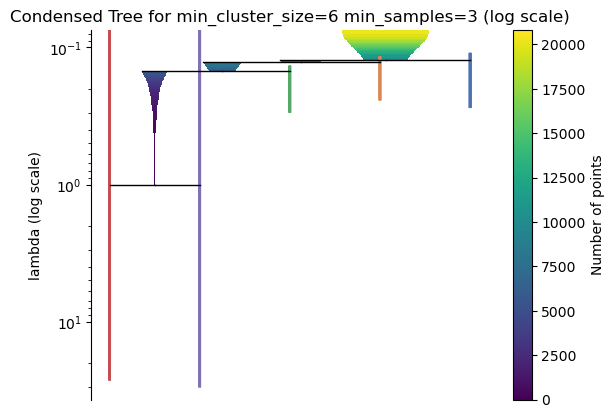

Silhouette Score (excluding outliers): 0.4983222275044033


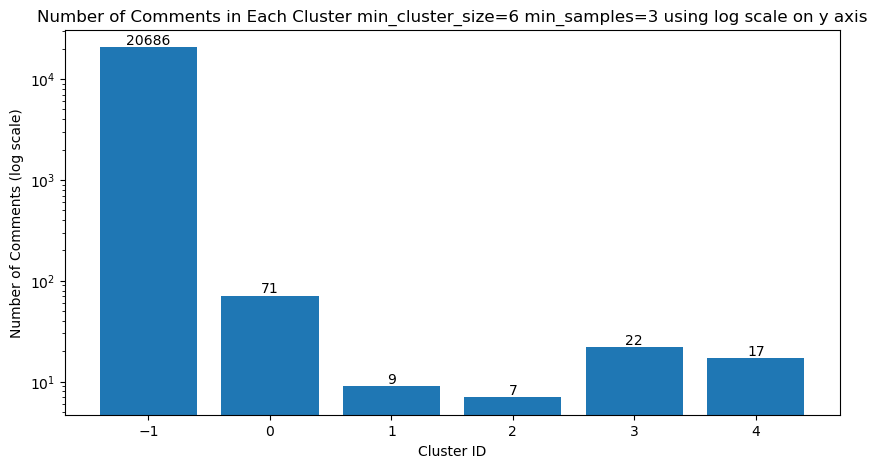

Cluster sizes:
 -1    20686
 0       71
 3       22
 4       17
 1        9
 2        7
Name: count, dtype: int64




Testing with hyperparameters:  {'min_cluster_size': 3, 'min_samples': 3}
Cluster persistence: [5.87480721e-05 1.03392875e-03 6.69480557e-03 1.37669667e-03
 3.87959828e-03 1.12827911e-03 2.07873537e-01 1.22653174e-02
 2.01161153e-01 4.53343021e-01]


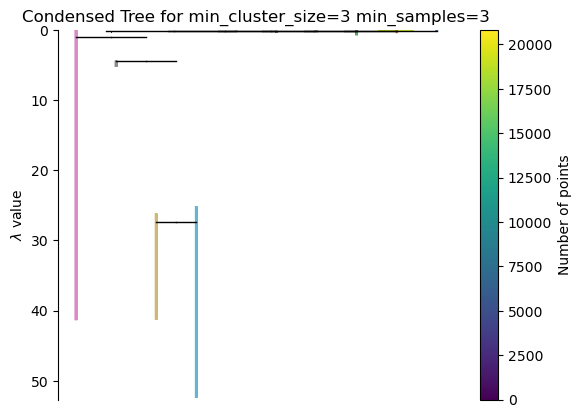

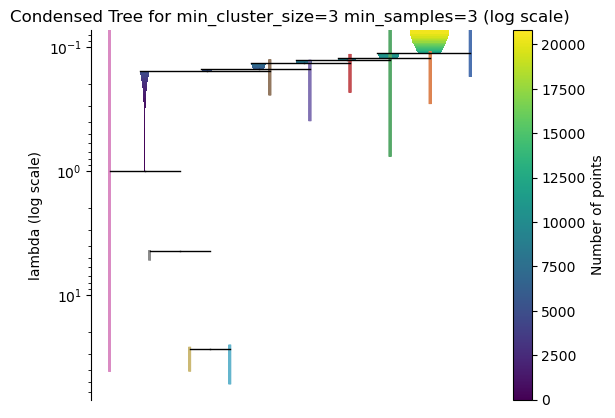

Silhouette Score (excluding outliers): 0.44930234240380185


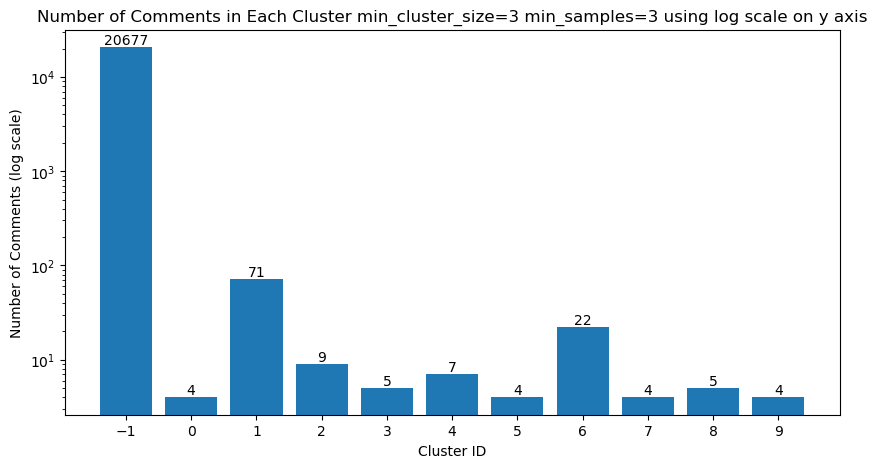

Cluster sizes:
 -1    20677
 1       71
 6       22
 2        9
 4        7
 3        5
 8        5
 7        4
 0        4
 9        4
 5        4
Name: count, dtype: int64






In [3]:
# hdbscan loop
labels_list = []
probabilities_list = []
hyperparameters_combinations = [
    {"min_cluster_size": 6, "min_samples": 6 },
    {"min_cluster_size": 6, "min_samples": 3 },
    {"min_cluster_size": 3, "min_samples": 3 }
]
cluster_persistence_list = []
for params in hyperparameters_combinations:
    print("Testing with hyperparameters: ", params)

    hdbscan = HDBSCAN(
        min_cluster_size=params["min_cluster_size"],
        min_samples=params["min_samples"],
        cluster_selection_method="leaf"
    )
    hdbscan_results = hdbscan.fit(X)
    
    #print the cluster persistence
    cluster_persistence_list.append(hdbscan_results.cluster_persistence_)
    print(f"Cluster persistence: {cluster_persistence_list[-1]}")

    #plot the condensed tree
    hdbscan_results.condensed_tree_.plot(select_clusters=True, selection_palette=sns.color_palette("deep", 10))
    plt.title(f"Condensed Tree for min_cluster_size={params['min_cluster_size']} min_samples={params['min_samples']}")
    plt.show()
    
    hdbscan_results.condensed_tree_.plot(select_clusters=True, selection_palette=sns.color_palette("deep", 10))
    plt.title(f"Condensed Tree for min_cluster_size={params['min_cluster_size']} min_samples={params['min_samples']} (log scale)")
    plt.yscale('log')
    plt.ylabel("lambda (log scale)")
    plt.show()

    labels = hdbscan_results.labels_
    labels_list.append(labels)
    #data["cluster"] = hdbscan_results.labels_
    np.save(f'hdbscan_labels_{params["min_cluster_size"]}_{params["min_samples"]}.npy', labels)
    # probabilities = hdbscan_results.probabilities_
    # probabilities_list.append(probabilities)
    # np.save(f'hdbscan_probabilities_{params["min_cluster_size"]}_{params["min_samples"]}.npy', probabilities)

    #Compute and print the silhouette score, ignoring outliers (label -1)
    try:
        mask = labels != -1
        score = silhouette_score(X[mask], labels[mask])
        print(f"Silhouette Score (excluding outliers): {score}")
    except Exception as e:
        print(f"Error calculating silhouette score: {e}")

    #Plot the number of comments for each cluster, with outliers as a separate bar
    plt.figure(figsize=(10, 5))
    cluster_sizes = pd.Series(labels).value_counts()
    plt.title(f"Number of Comments in Each Cluster min_cluster_size={params['min_cluster_size']} min_samples={params['min_samples']} using log scale on y axis")
    #plt.bar(["outliers"]+[str(i) for i in range(0, cluster_sizes.shape[0]-1)], cluster_sizes.values)
    bars = plt.bar(cluster_sizes.index, cluster_sizes.values)
    plt.xlabel("Cluster ID")
    plt.ylabel("Number of Comments (log scale)")
    plt.xticks(cluster_sizes.index)
    #log scale on y axis
    plt.yscale('log')
    plt.bar_label(bars, labels=cluster_sizes.values)
    plt.show()
    print("Cluster sizes:\n", cluster_sizes)

    # plt.figure(figsize=(8, 5))
    # for i in range(0, cluster_sizes.shape[0]):
    #         sns.kdeplot(
    #         probabilities[labels==i],
    #         label=f"Cluster {i}"
    #     )
    # plt.legend()
    # plt.title("Probability Density per Cluster")
    # plt.show()

    print("\n\n\n")

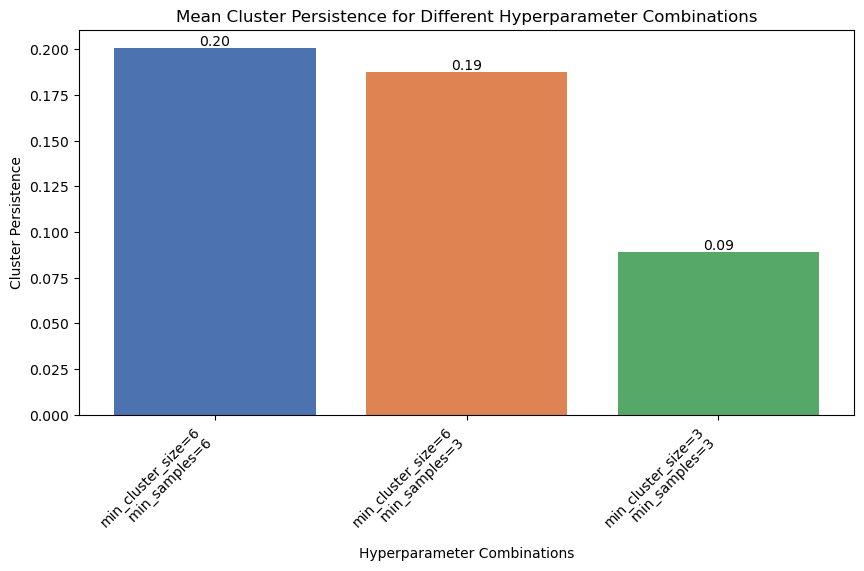

In [4]:
#plot the cluster persistence for each hyperparameter combination
plt.figure(figsize=(10, 5))
#use mean persistence, and 0 when no clusters are found
persistence_values = [
    float(np.mean(cp)) if np.asarray(cp).size > 0 else 0.0
    for cp in cluster_persistence_list
]
bars = plt.bar(
    range(len(hyperparameters_combinations)),
    persistence_values,
    color=sns.color_palette("deep", len(hyperparameters_combinations))
)
plt.bar_label(bars, fmt="%.2f")
plt.xticks(range(len(hyperparameters_combinations)), [f"min_cluster_size={params['min_cluster_size']}\n min_samples={params['min_samples']}" for params in hyperparameters_combinations], rotation=45, ha='right')    
plt.xlabel("Hyperparameter Combinations")
plt.ylabel("Cluster Persistence")
plt.title("Mean Cluster Persistence for Different Hyperparameter Combinations")
plt.show()

In [5]:
# index = int(input("Index of the hyperparameters combination to visualize (0, 1, or 2): "))
# data['cluster']=labels_list[index]
# #probabilities=probabilities_list[index]
# params = hyperparameters_combinations[index]

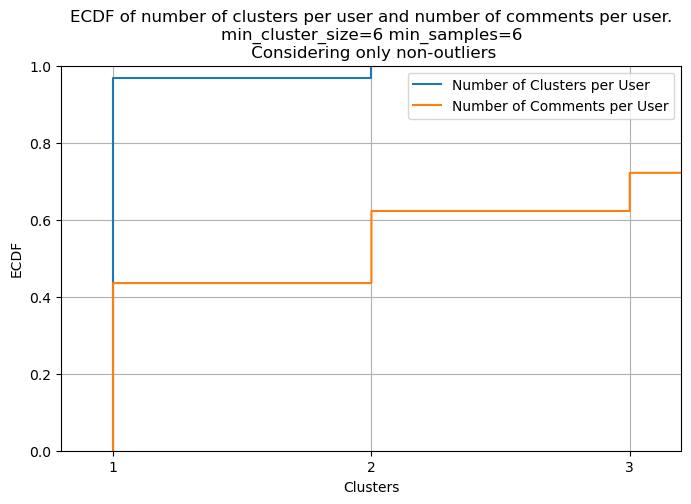

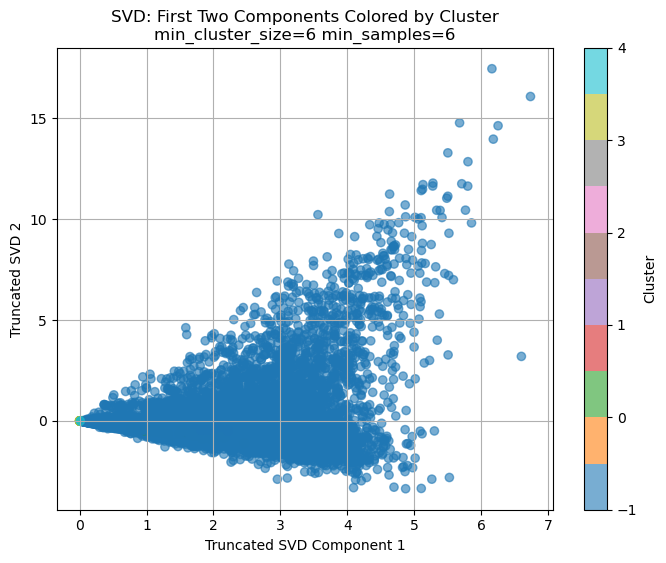

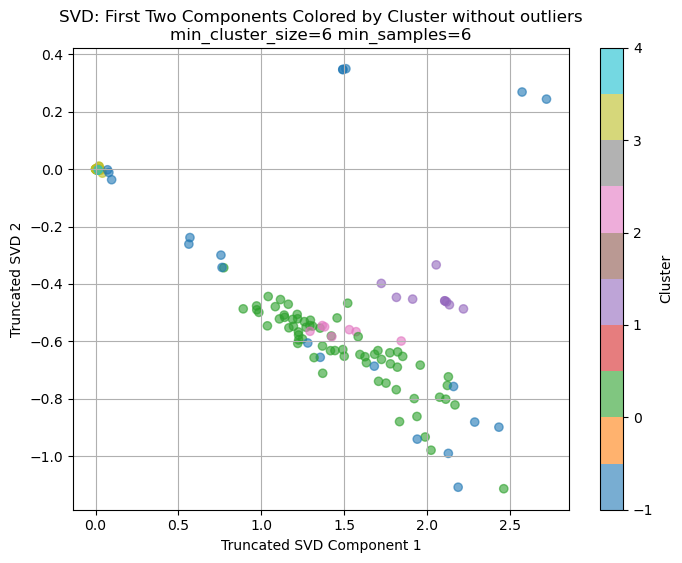

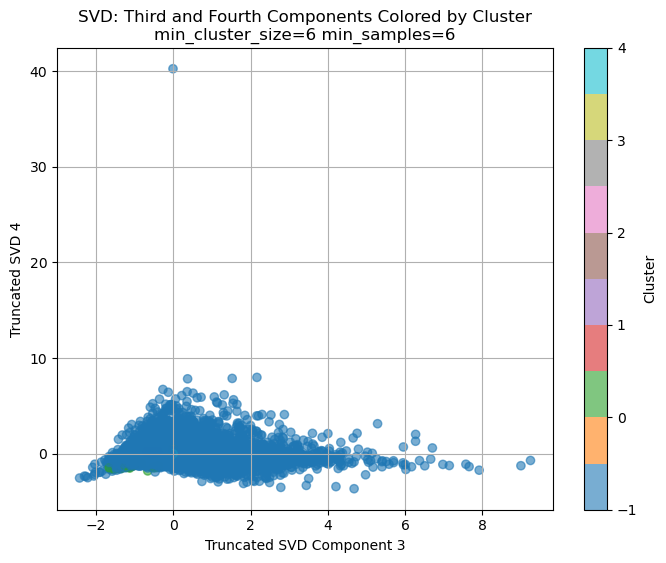

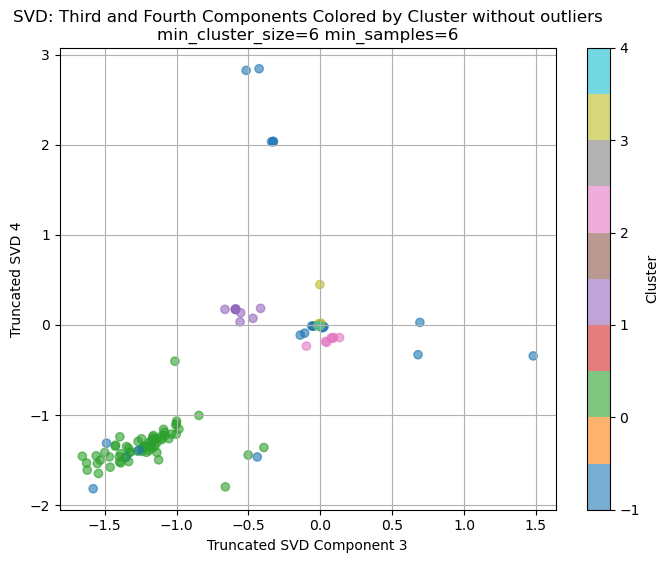

cluster 0 has 66 comments


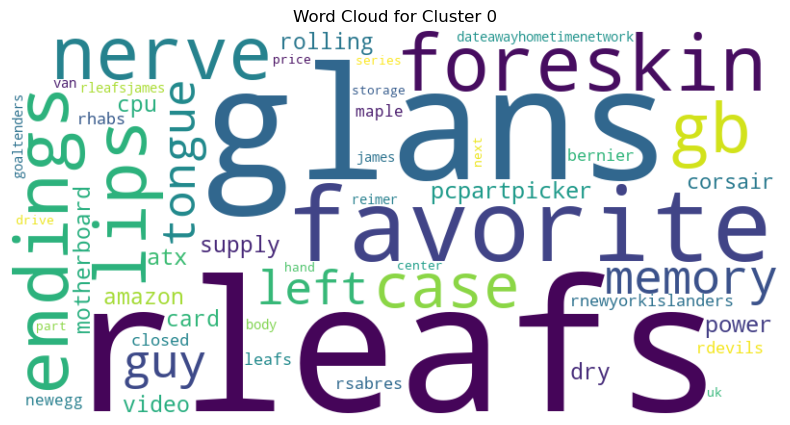

cluster -1 has 20694 comments


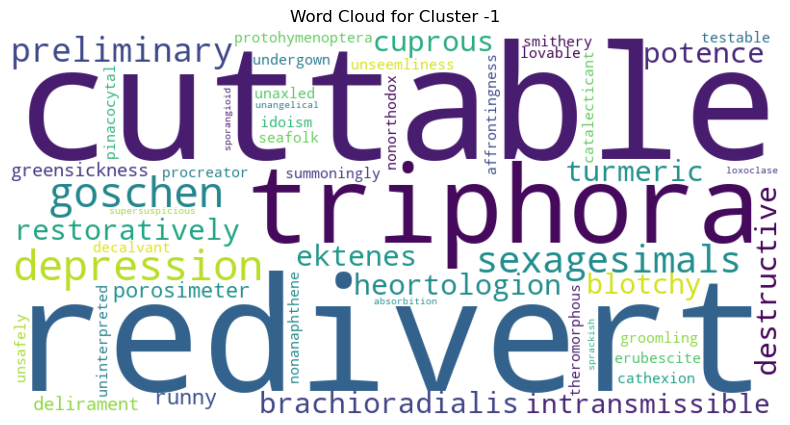

cluster 3 has 19 comments


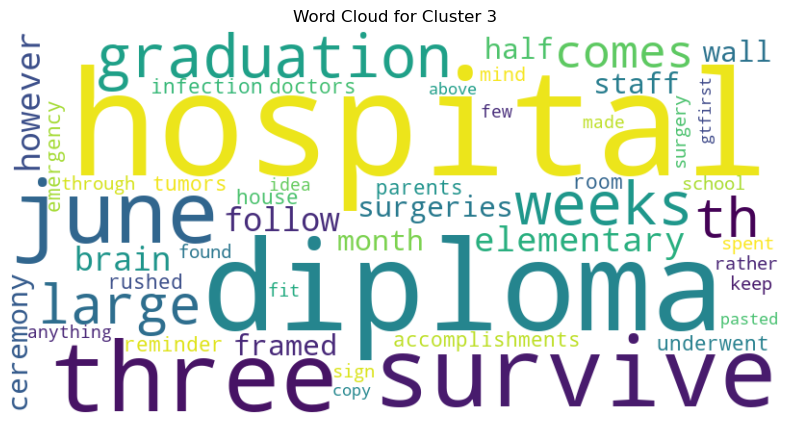

cluster 4 has 17 comments


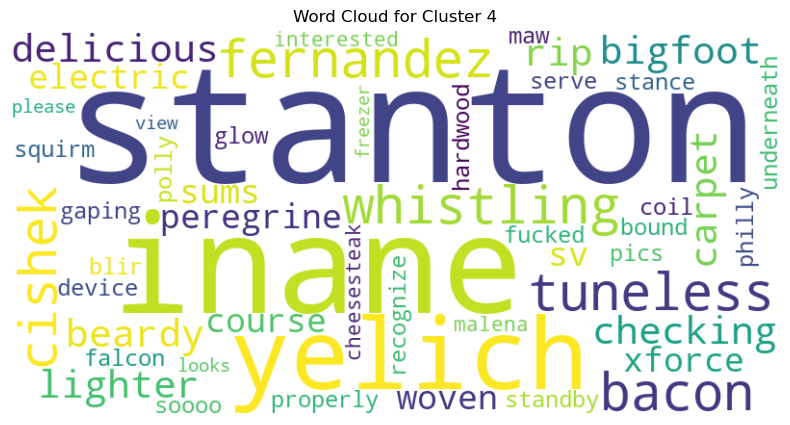

cluster 1 has 9 comments


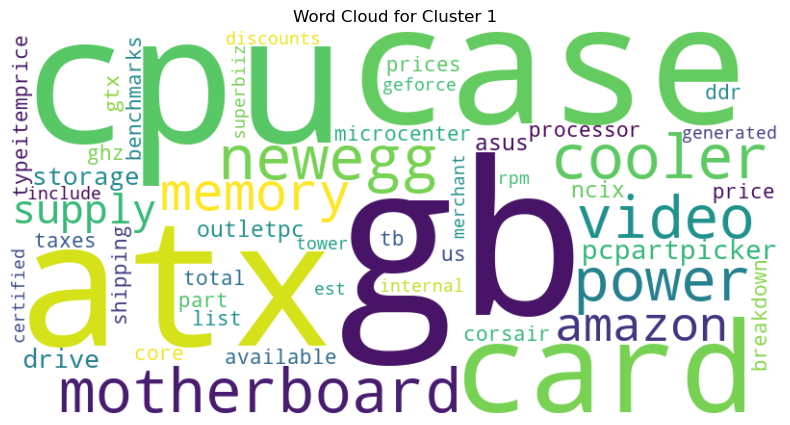

cluster 2 has 7 comments


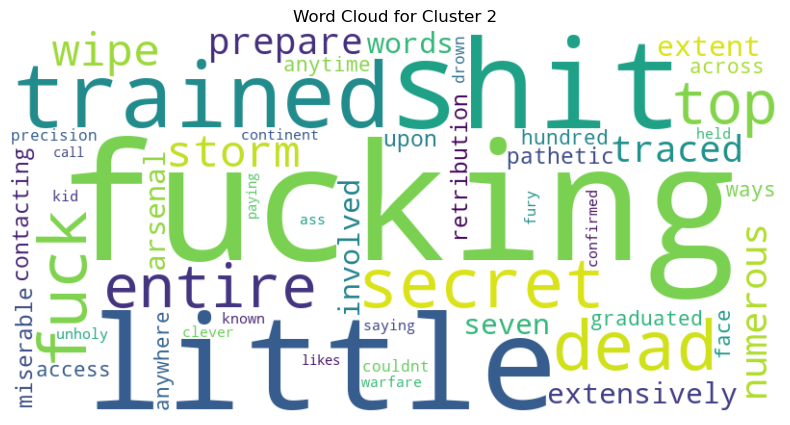

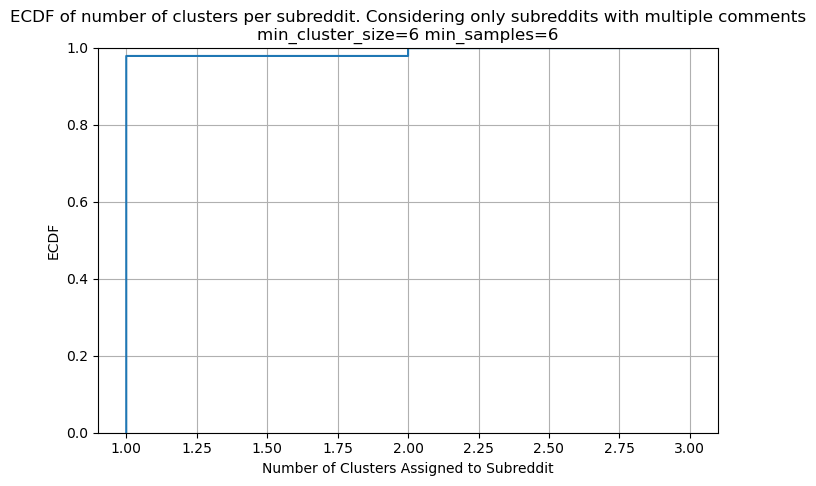

Cluster 0 has 66 comments and 5 subreddits


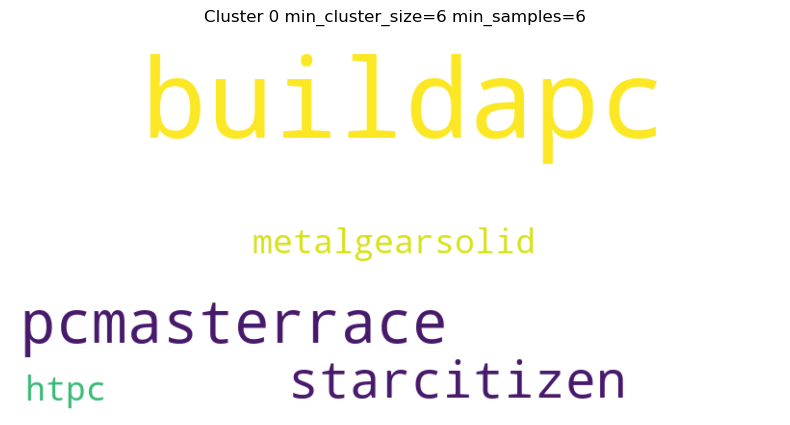

Cluster -1 has 21 comments and 8 subreddits


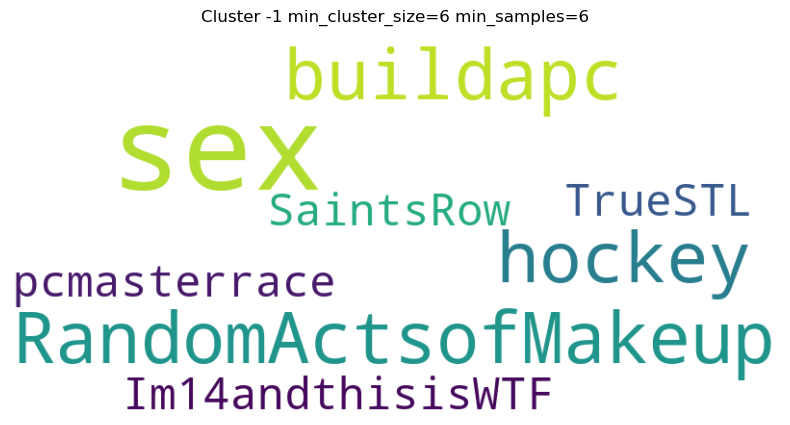

Cluster 3 has 19 comments and 19 subreddits


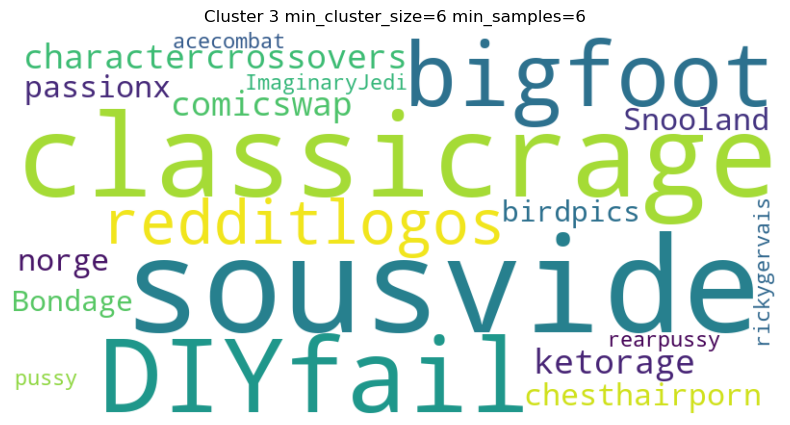

Cluster 4 has 13 comments and 8 subreddits


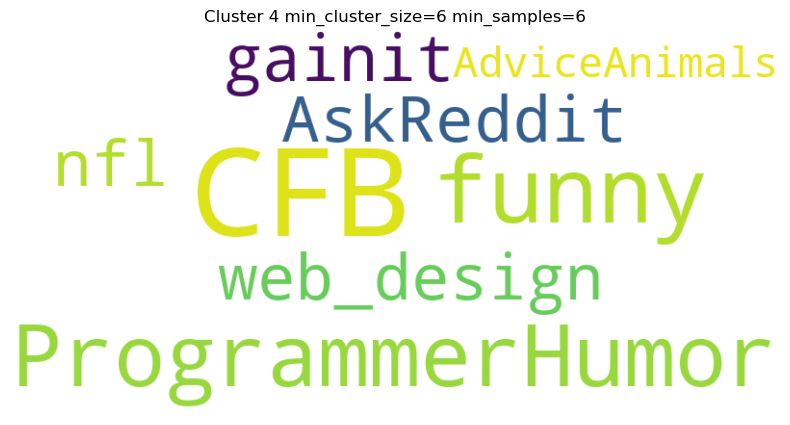

Cluster 1 has 9 comments and 9 subreddits


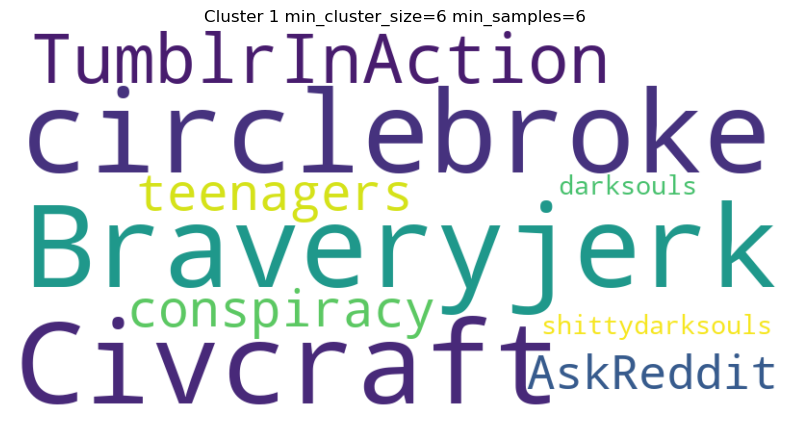

Cluster 2 has 7 comments and 1 subreddits


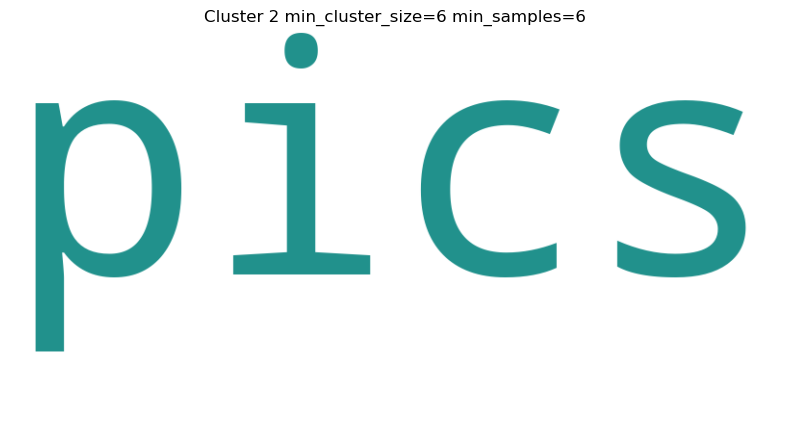

ARI: 0.0002862886737147786
NMI: 0.0099348743847086
AMI: 0.004306031237303847
Considerind only non-outliers:
ARI: 0.7043316828529271
NMI: 0.6608875248495687
AMI: 0.5393835607571064


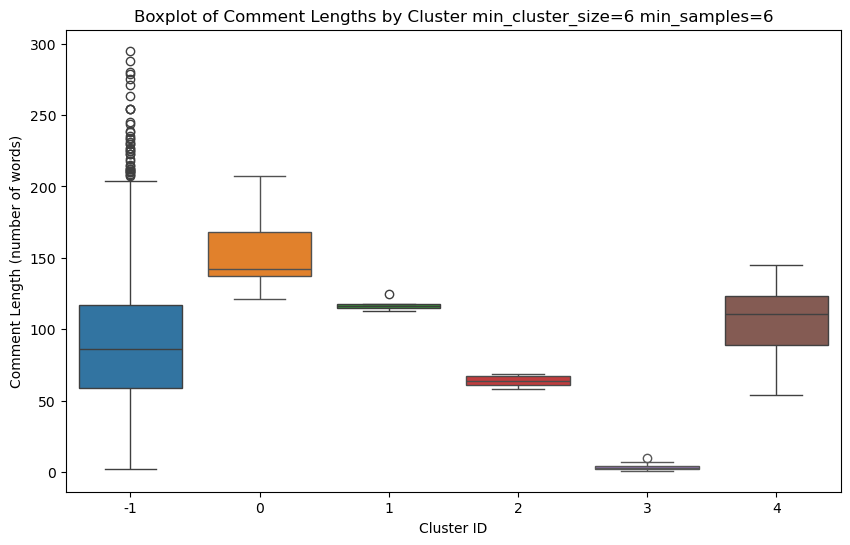

Cluster -1:
  Min length: 2 words
  25th percentile: 59.0 words
  Average length: 86.88 words
  75th percentile: 117.0 words
  Max length: 295 words
Cluster 0:
  Min length: 121 words
  25th percentile: 137.0 words
  Average length: 151.65 words
  75th percentile: 168.0 words
  Max length: 207 words
Cluster 1:
  Min length: 113 words
  25th percentile: 115.0 words
  Average length: 116.78 words
  75th percentile: 118.0 words
  Max length: 125 words
Cluster 2:
  Min length: 58 words
  25th percentile: 61.0 words
  Average length: 63.86 words
  75th percentile: 67.0 words
  Max length: 69 words
Cluster 3:
  Min length: 1 words
  25th percentile: 2.0 words
  Average length: 3.26 words
  75th percentile: 4.0 words
  Max length: 10 words
Cluster 4:
  Min length: 54 words
  25th percentile: 89.0 words
  Average length: 104.82 words
  75th percentile: 123.0 words
  Max length: 145 words
Cluster 5:
  Min length: nan words
  25th percentile: nan words
  Average length: nan words
  75th percenti

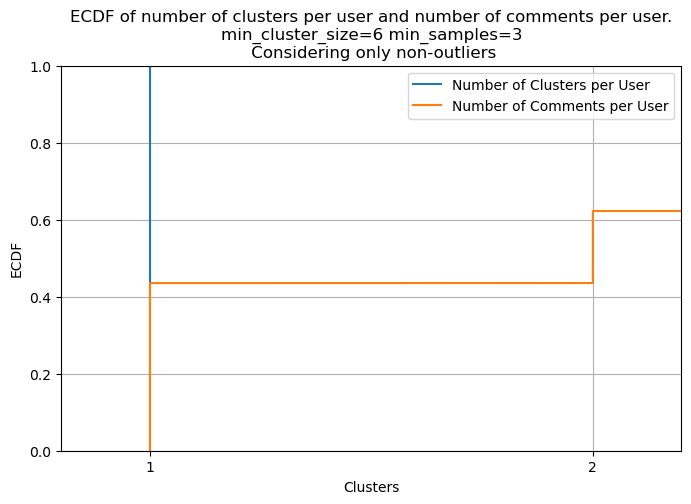

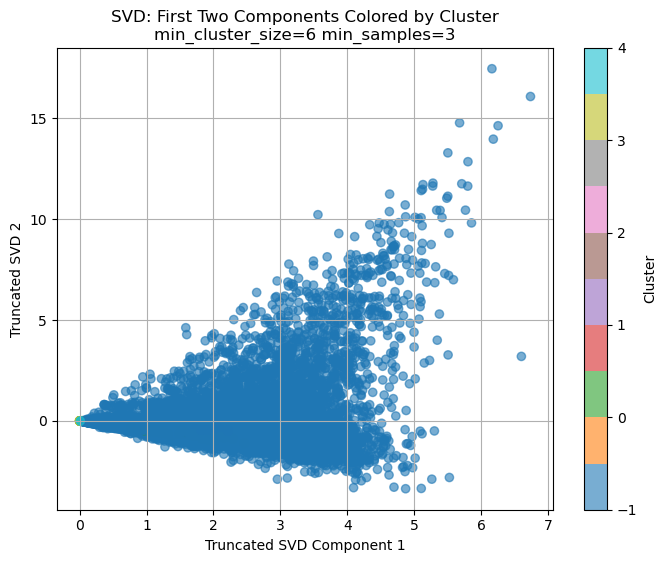

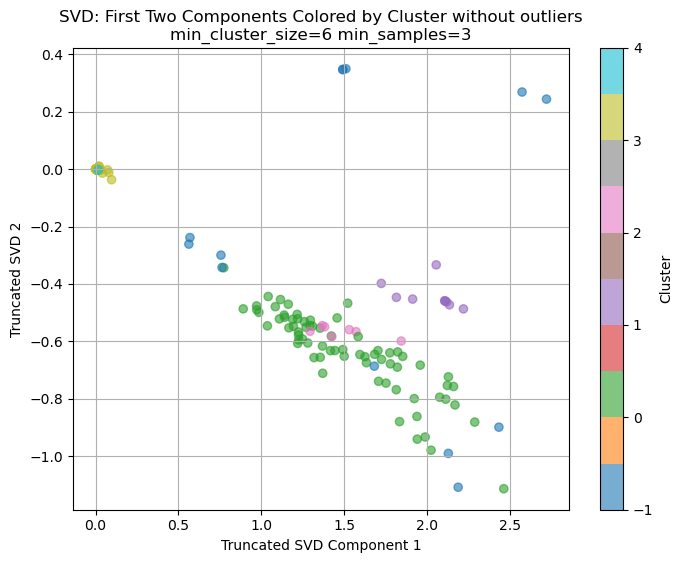

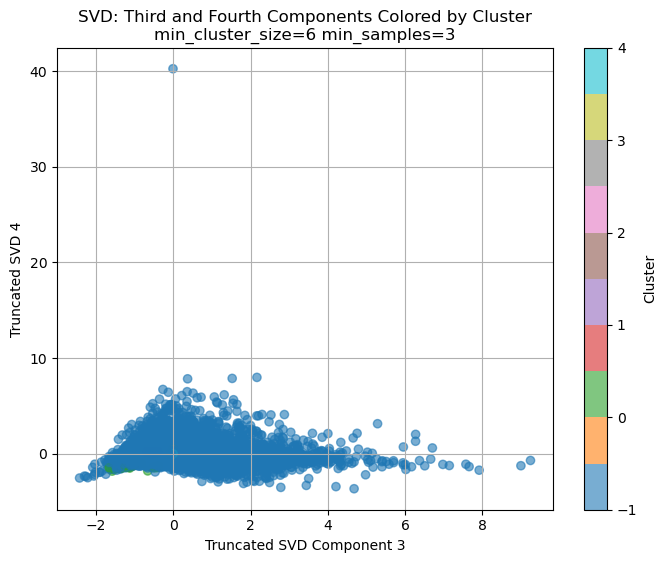

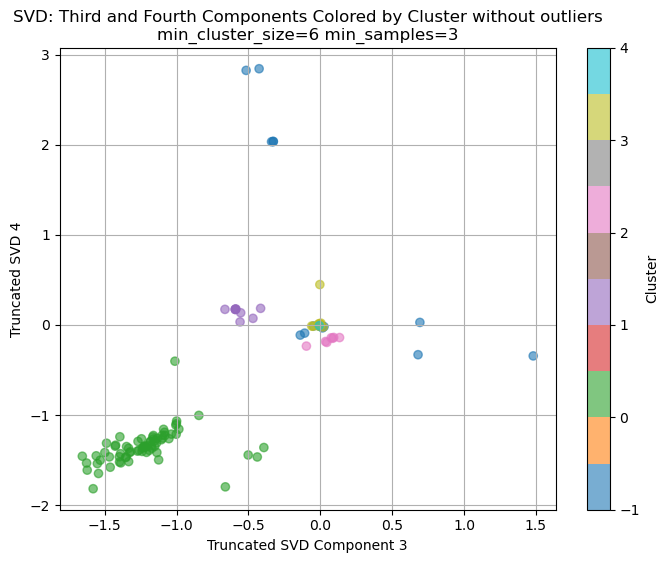

cluster 0 has 71 comments


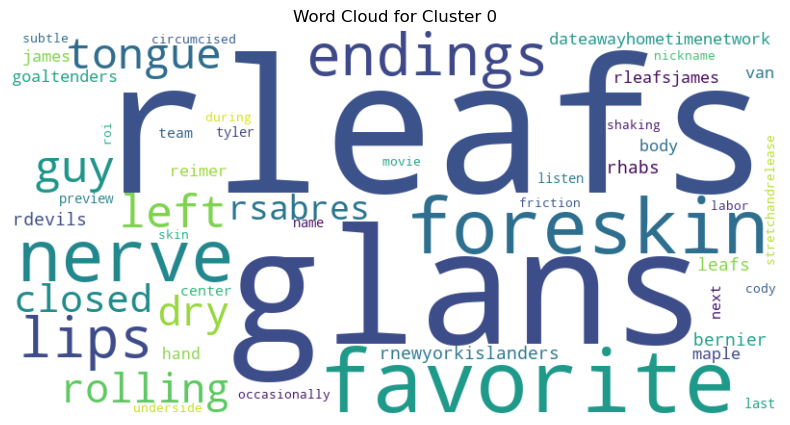

cluster 3 has 22 comments


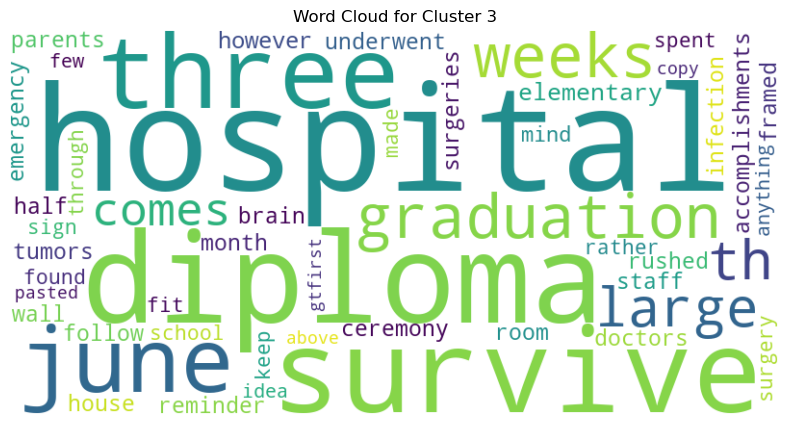

cluster 4 has 17 comments


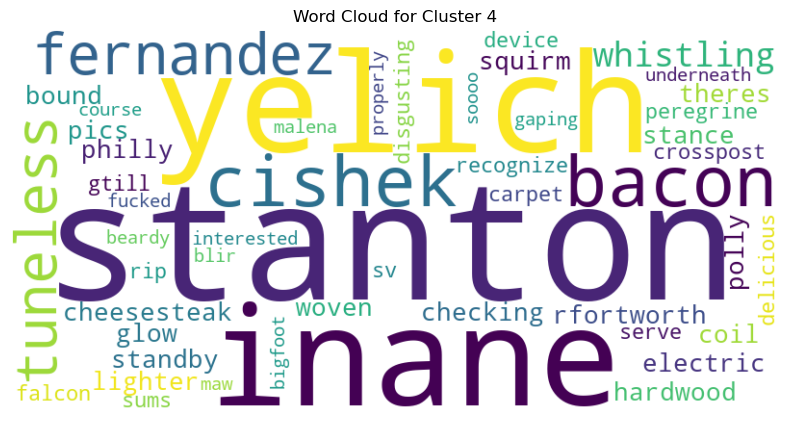

cluster -1 has 20686 comments


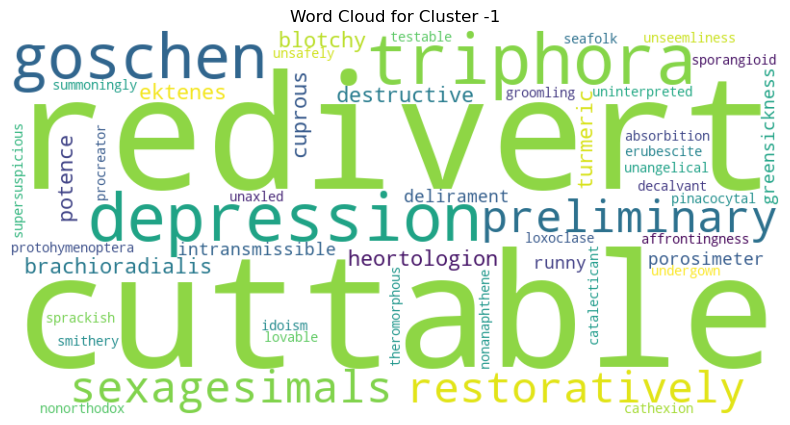

cluster 1 has 9 comments


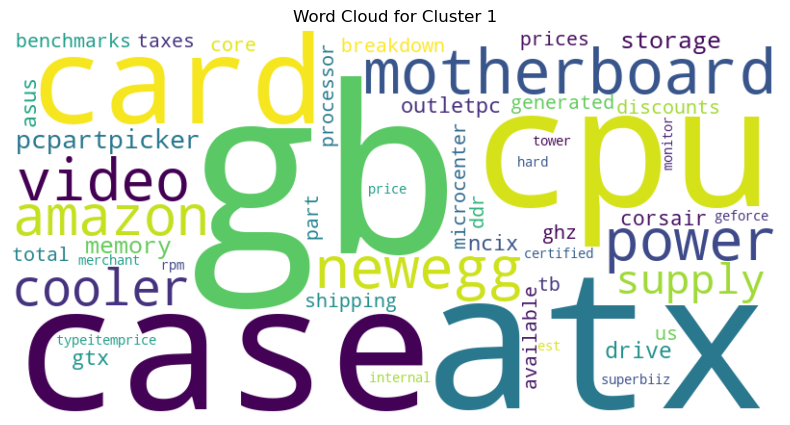

cluster 2 has 7 comments


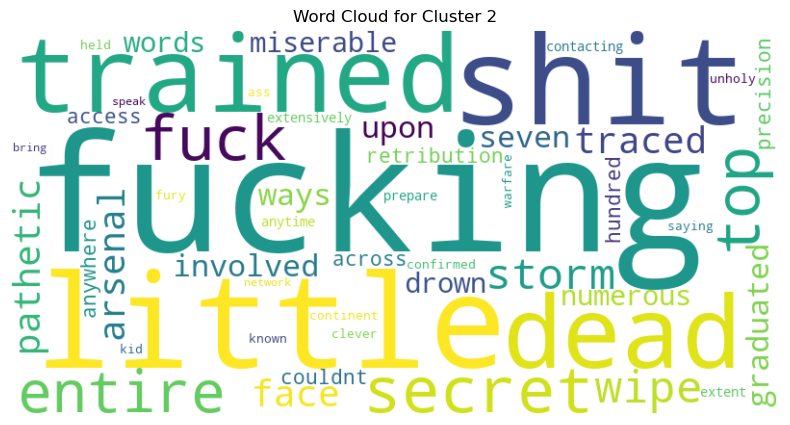

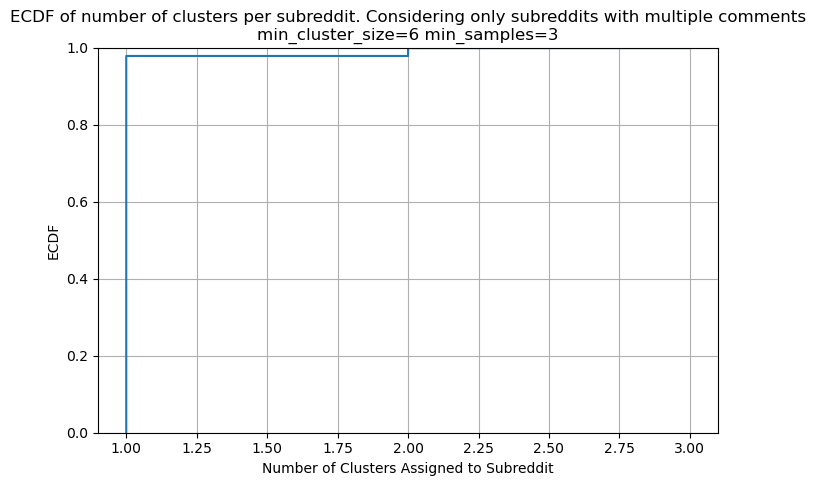

Cluster 0 has 71 comments and 5 subreddits


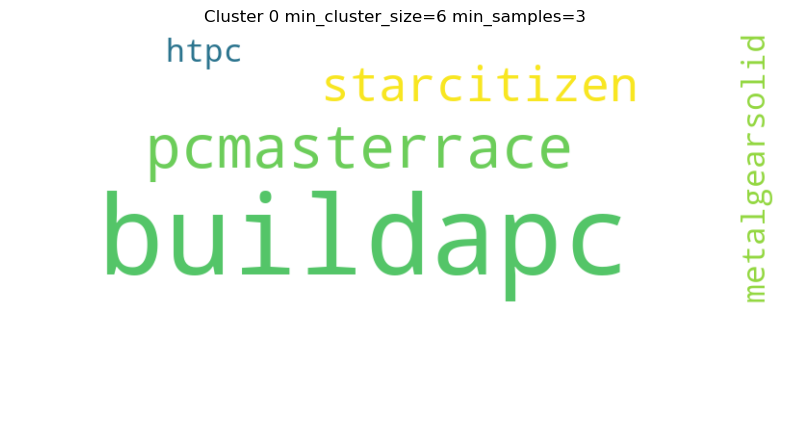

Cluster 3 has 22 comments and 22 subreddits


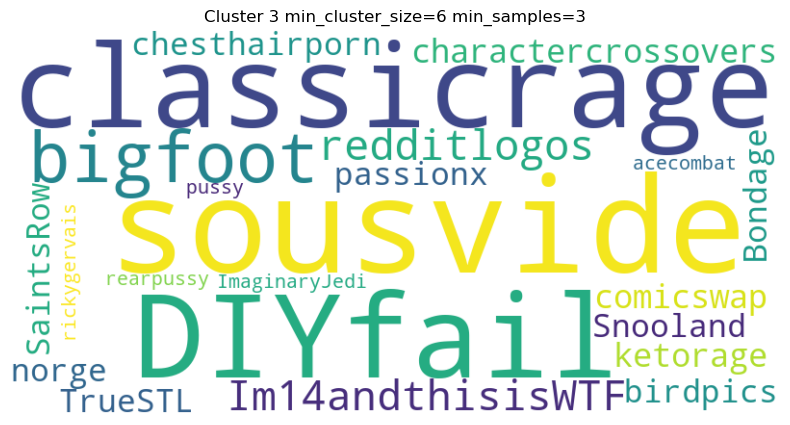

Cluster 4 has 13 comments and 8 subreddits


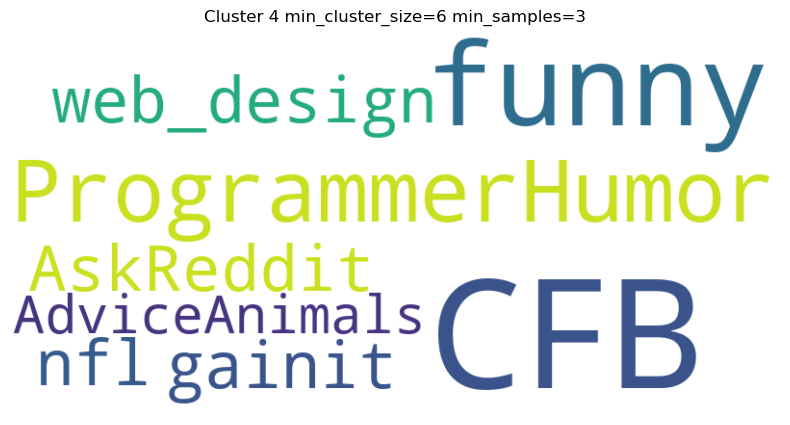

Cluster -1 has 13 comments and 3 subreddits


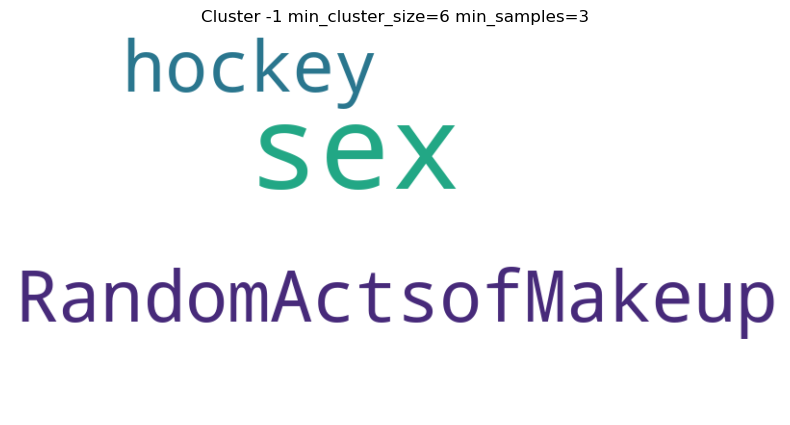

Cluster 1 has 9 comments and 9 subreddits


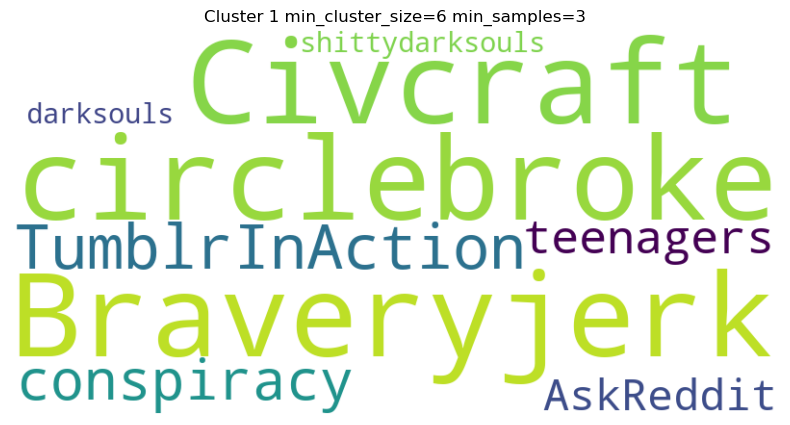

Cluster 2 has 7 comments and 1 subreddits


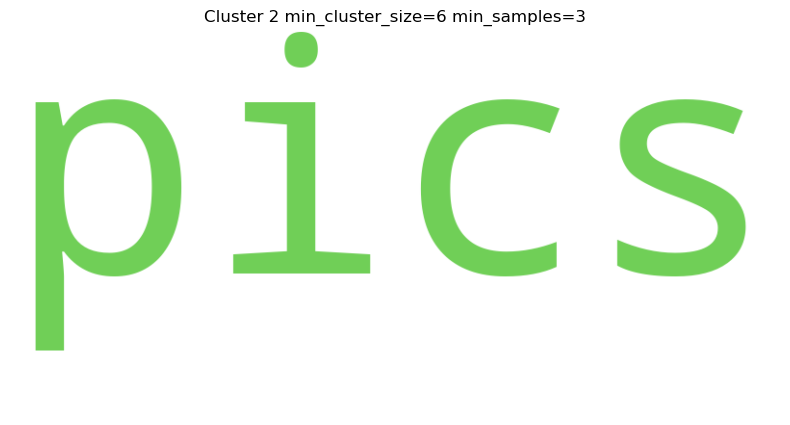

ARI: 0.0003142662397816195
NMI: 0.01068437299011451
AMI: 0.004803387030928391
Considerind only non-outliers:
ARI: 0.6951831199036064
NMI: 0.651319400853925
AMI: 0.529225344306866


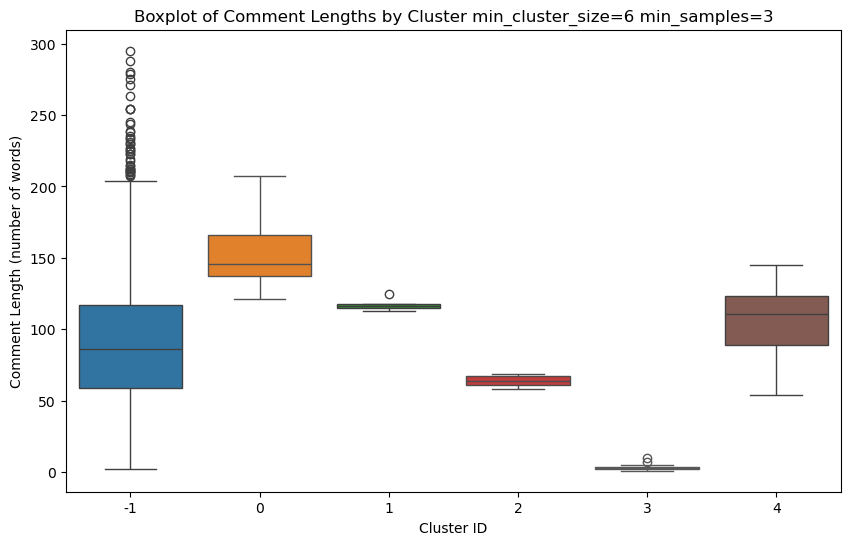

Cluster -1:
  Min length: 2 words
  25th percentile: 59.0 words
  Average length: 86.87 words
  75th percentile: 117.0 words
  Max length: 295 words
Cluster 0:
  Min length: 121 words
  25th percentile: 137.5 words
  Average length: 152.06 words
  75th percentile: 166.0 words
  Max length: 207 words
Cluster 1:
  Min length: 113 words
  25th percentile: 115.0 words
  Average length: 116.78 words
  75th percentile: 118.0 words
  Max length: 125 words
Cluster 2:
  Min length: 58 words
  25th percentile: 61.0 words
  Average length: 63.86 words
  75th percentile: 67.0 words
  Max length: 69 words
Cluster 3:
  Min length: 1 words
  25th percentile: 2.0 words
  Average length: 3.14 words
  75th percentile: 3.75 words
  Max length: 10 words
Cluster 4:
  Min length: 54 words
  25th percentile: 89.0 words
  Average length: 104.82 words
  75th percentile: 123.0 words
  Max length: 145 words
Cluster 5:
  Min length: nan words
  25th percentile: nan words
  Average length: nan words
  75th percent

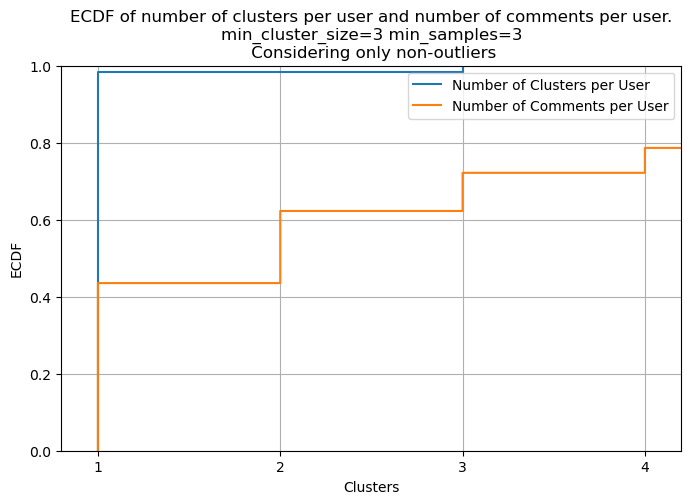

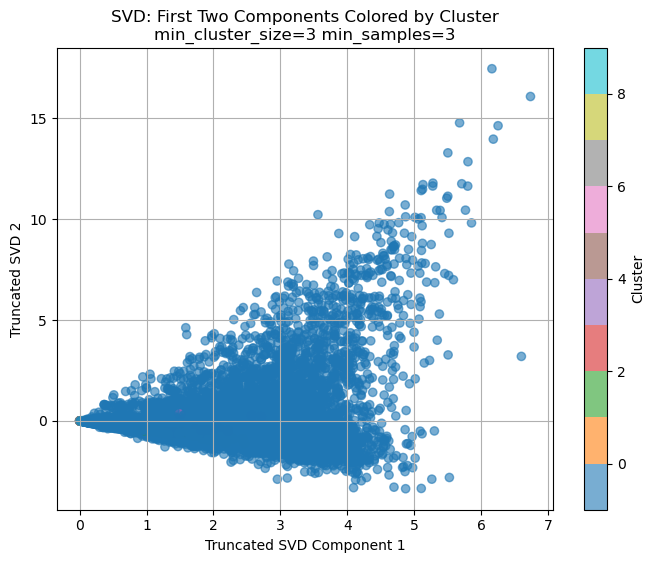

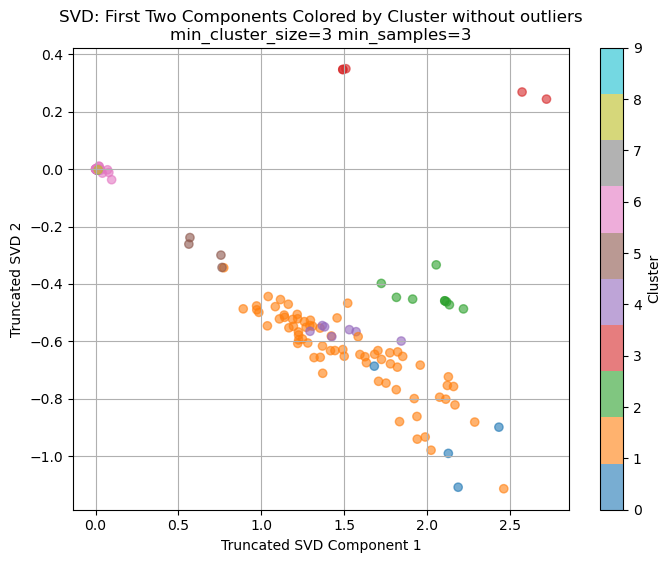

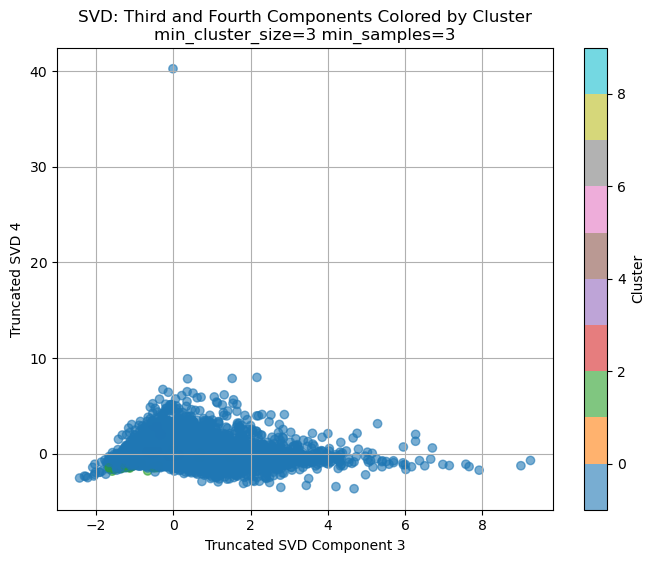

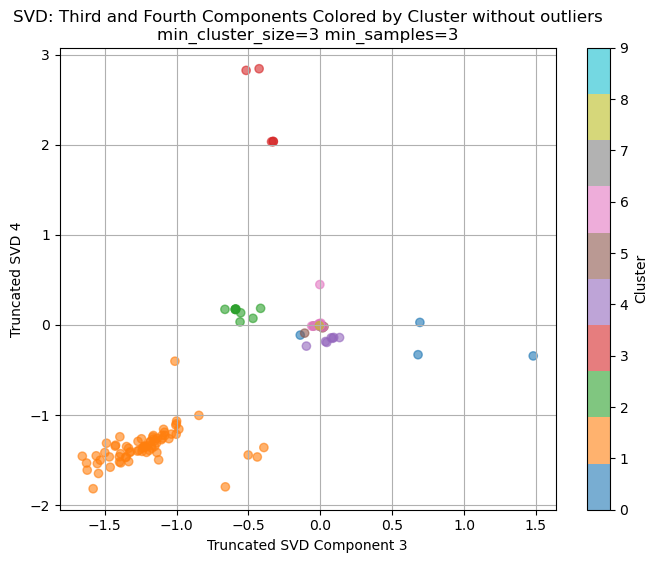

cluster 1 has 71 comments


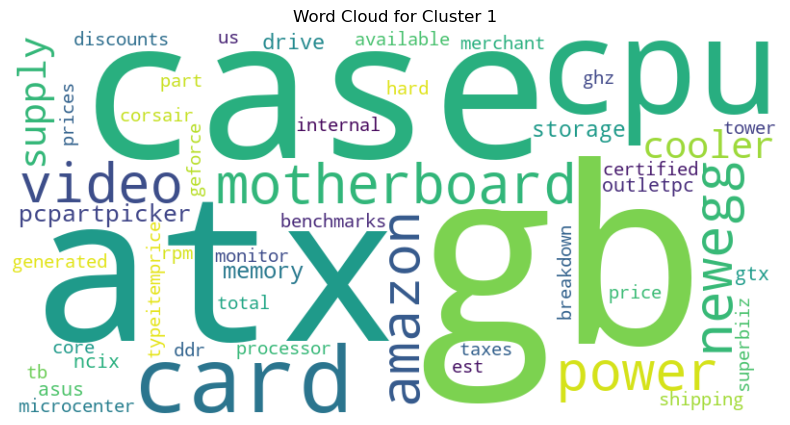

cluster 6 has 22 comments


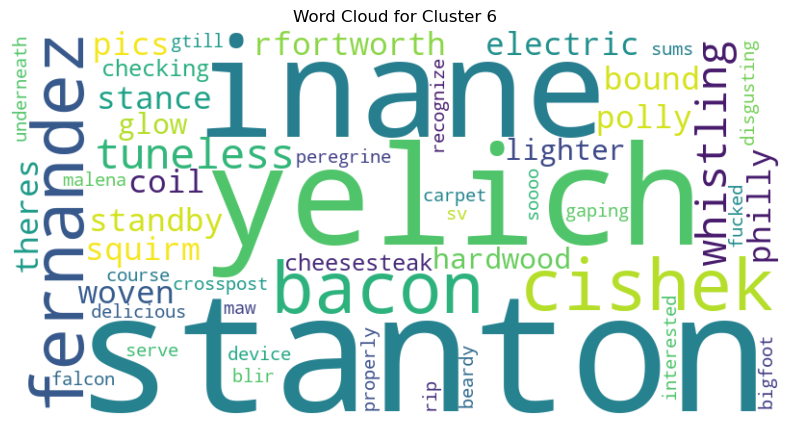

cluster 2 has 9 comments


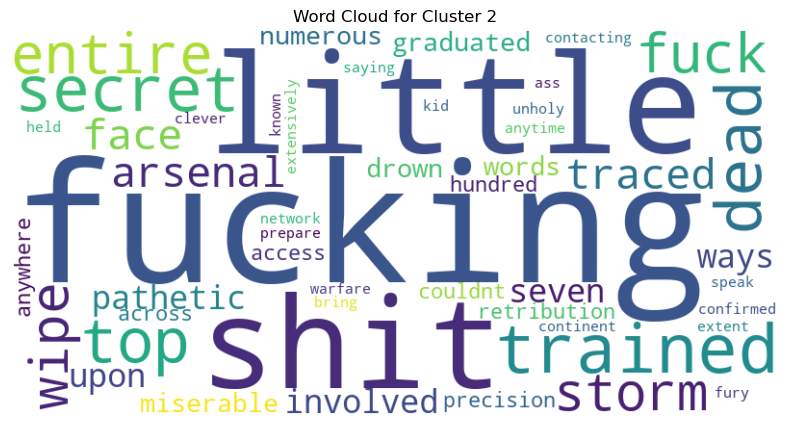

cluster 4 has 7 comments


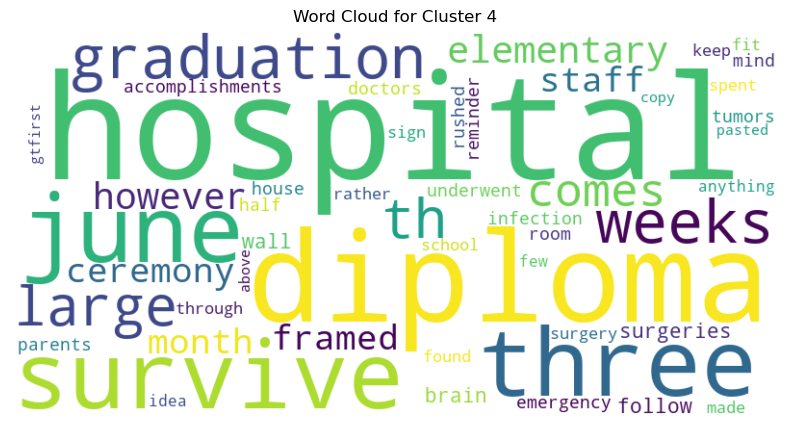

cluster 3 has 5 comments


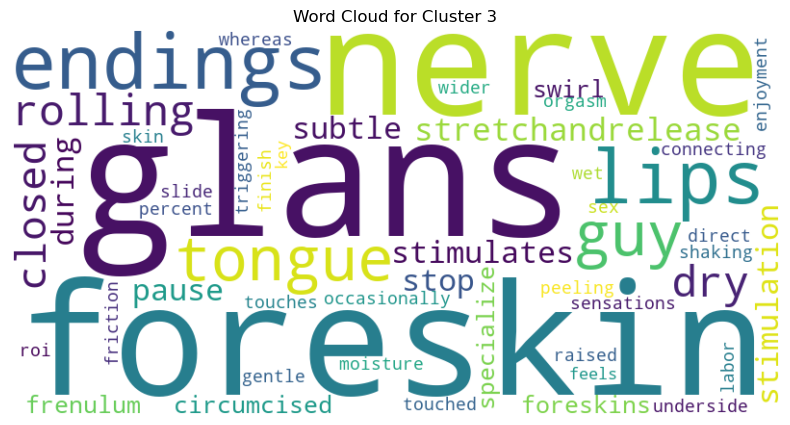

cluster 8 has 5 comments


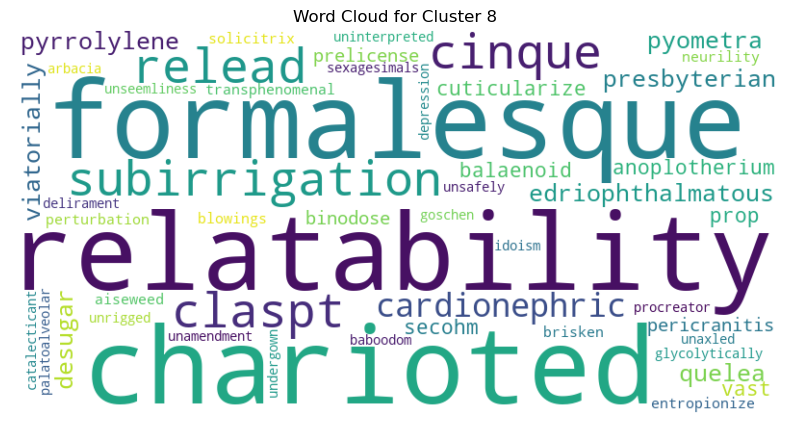

cluster 7 has 4 comments


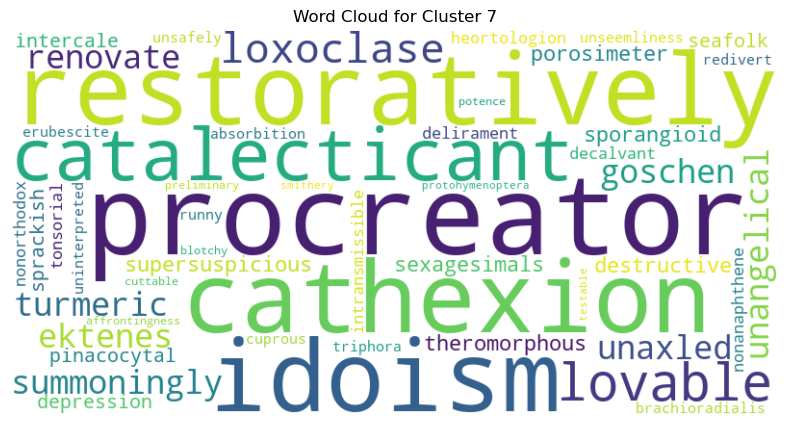

cluster 0 has 4 comments


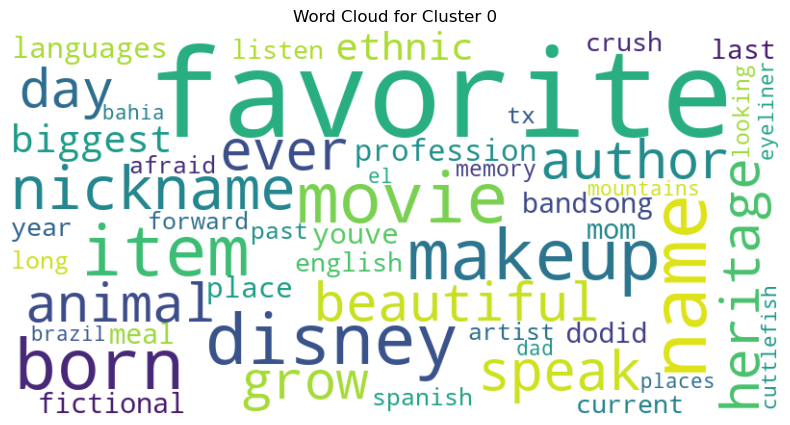

cluster 9 has 4 comments


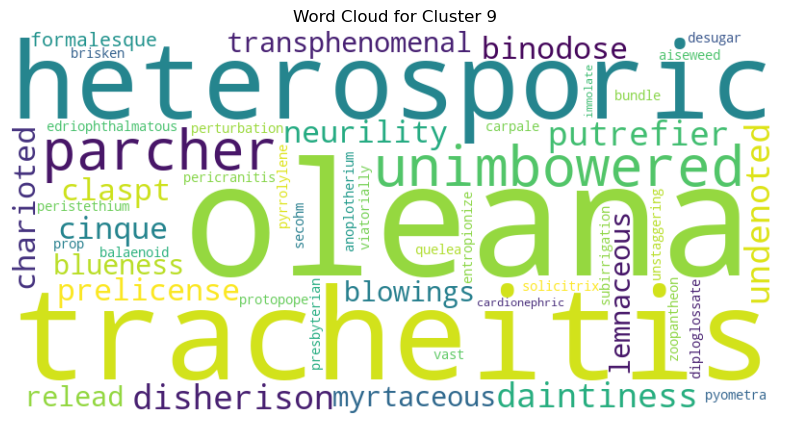

cluster 5 has 4 comments


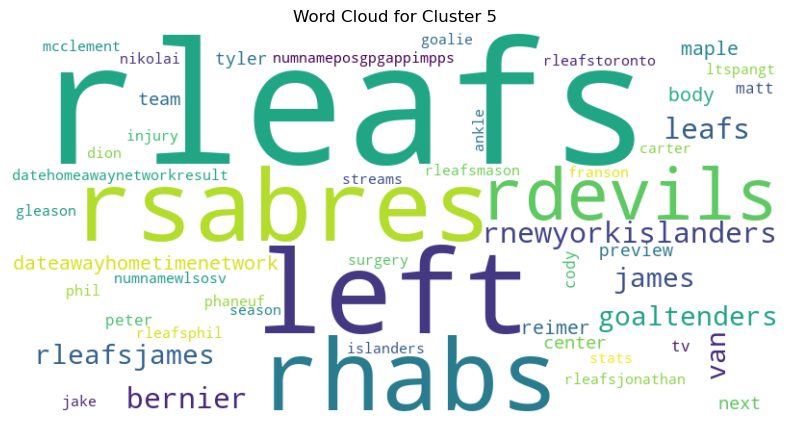

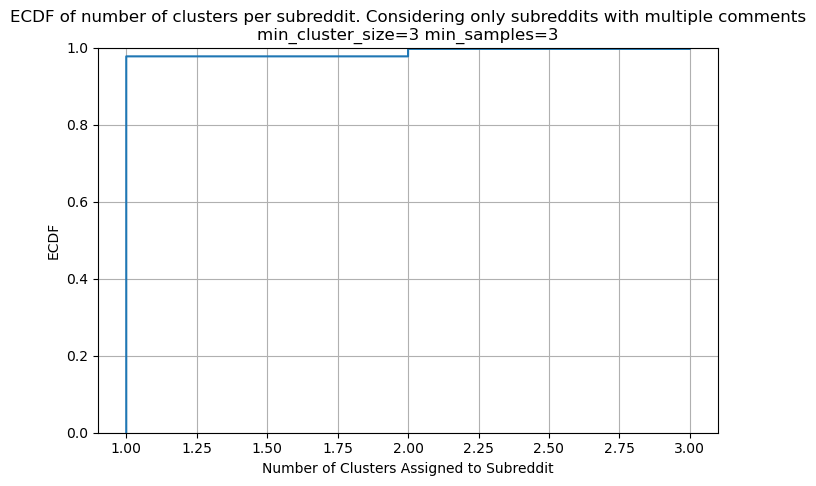

Cluster 1 has 71 comments and 5 subreddits


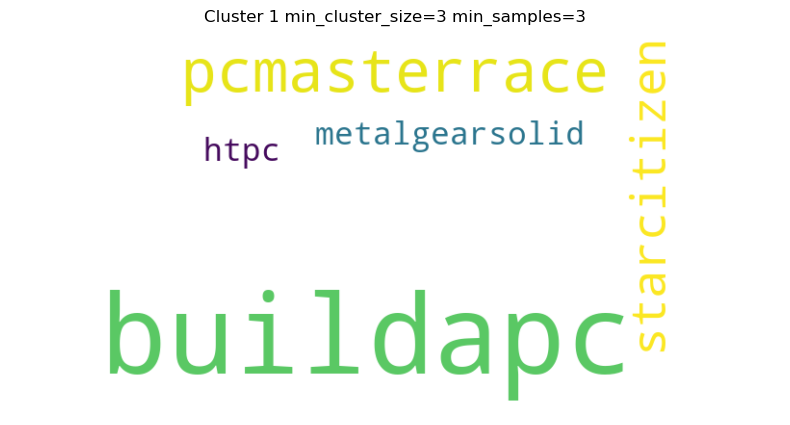

Cluster 6 has 22 comments and 22 subreddits


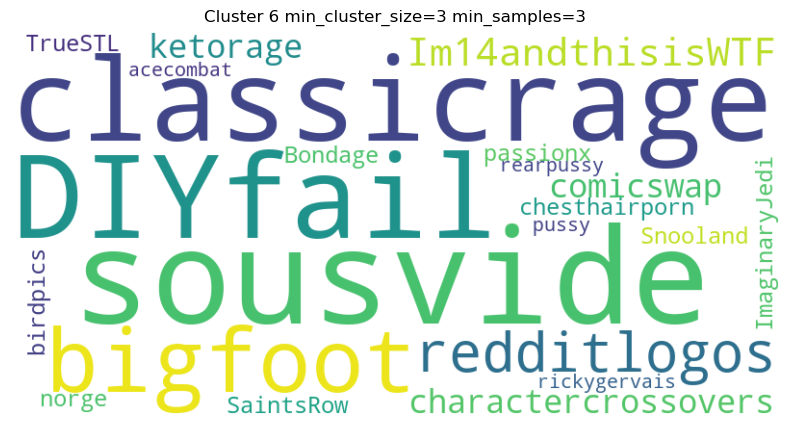

Cluster 2 has 9 comments and 9 subreddits


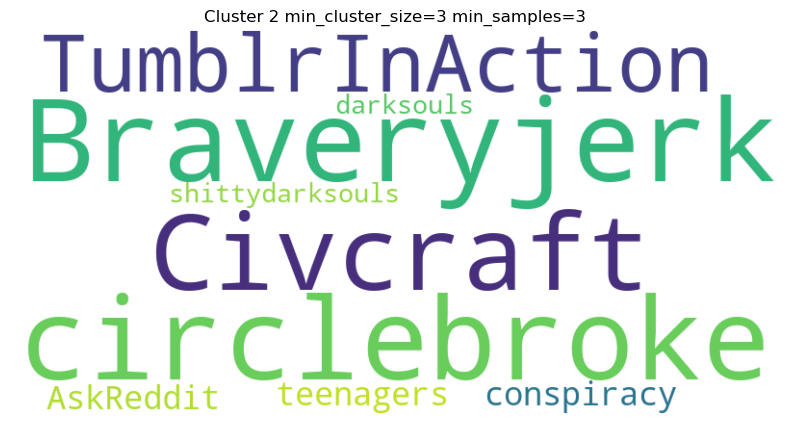

Cluster 4 has 7 comments and 1 subreddits


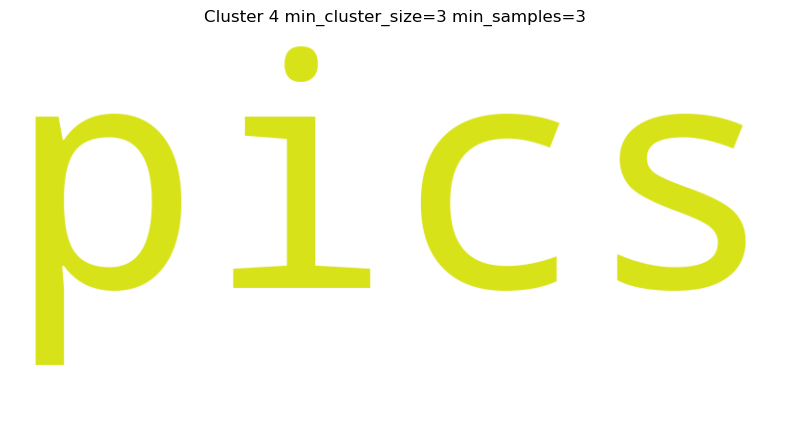

Cluster 3 has 5 comments and 1 subreddits


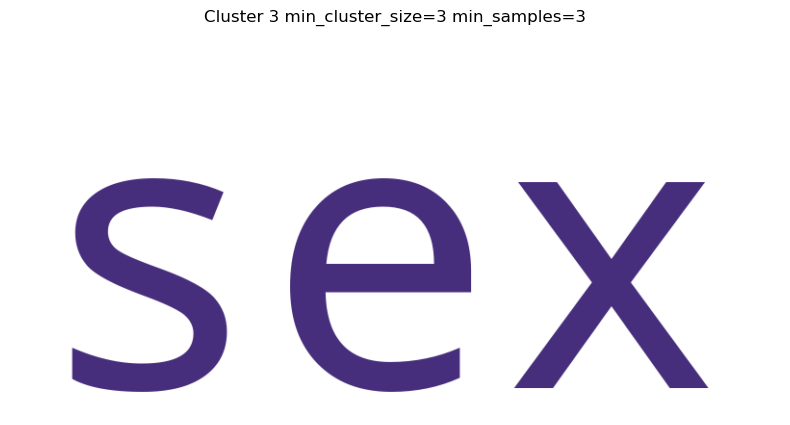

Cluster 8 has 5 comments and 4 subreddits


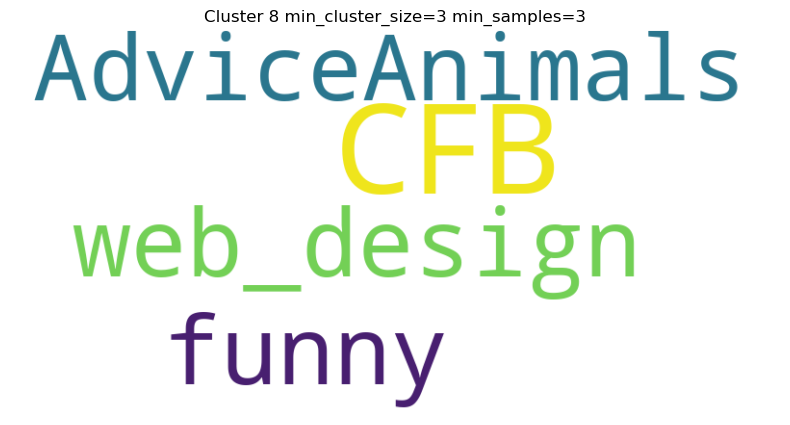

Cluster 7 has 4 comments and 3 subreddits


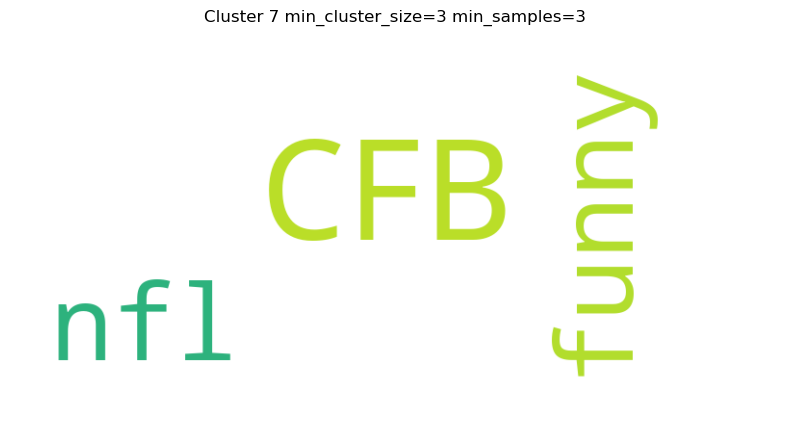

Cluster 0 has 4 comments and 1 subreddits


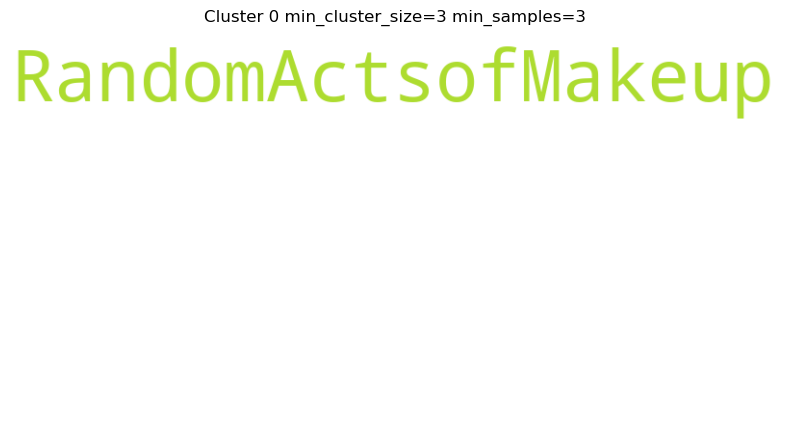

Cluster 9 has 4 comments and 3 subreddits


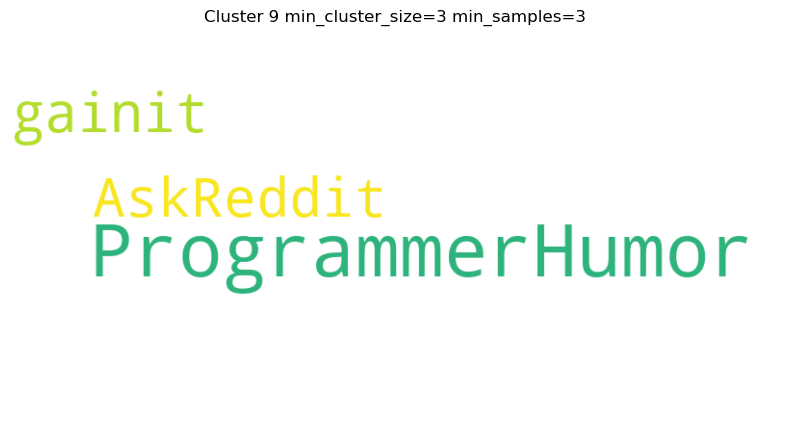

Cluster 5 has 4 comments and 1 subreddits


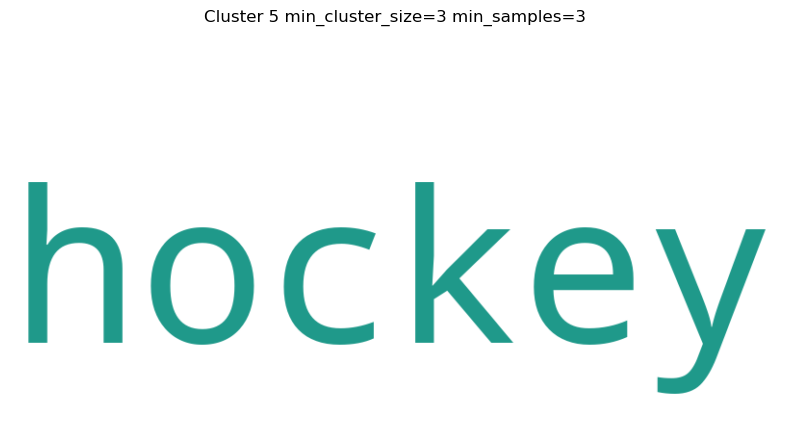

ARI: 0.00033841864910435756
NMI: 0.011804974075674341
AMI: 0.004924392720239928
Considerind only non-outliers:
ARI: 0.7355330220973773
NMI: 0.7422719465818624
AMI: 0.6236229566509316


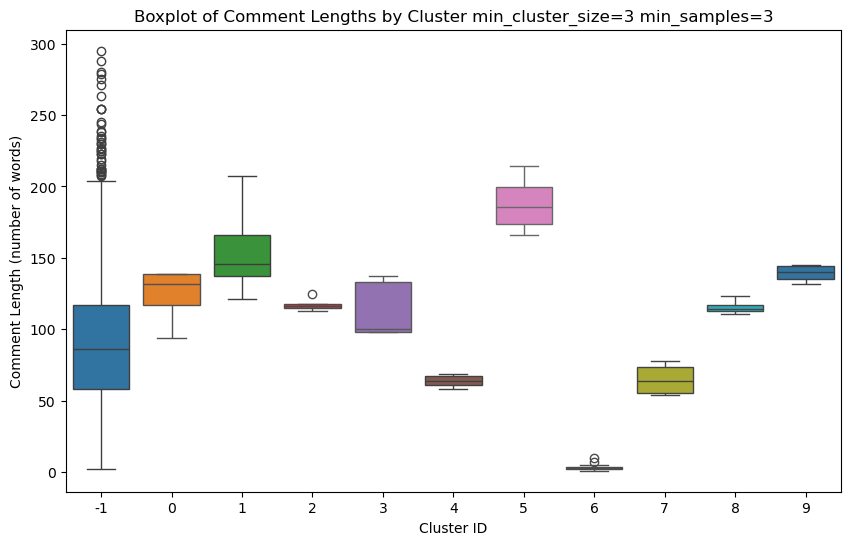

Cluster -1:
  Min length: 2 words
  25th percentile: 58.0 words
  Average length: 86.84 words
  75th percentile: 117.0 words
  Max length: 295 words
Cluster 0:
  Min length: 94 words
  25th percentile: 117.25 words
  Average length: 124.25 words
  75th percentile: 139.0 words
  Max length: 139 words
Cluster 1:
  Min length: 121 words
  25th percentile: 137.5 words
  Average length: 152.06 words
  75th percentile: 166.0 words
  Max length: 207 words
Cluster 2:
  Min length: 113 words
  25th percentile: 115.0 words
  Average length: 116.78 words
  75th percentile: 118.0 words
  Max length: 125 words
Cluster 3:
  Min length: 98 words
  25th percentile: 98.0 words
  Average length: 113.20 words
  75th percentile: 133.0 words
  Max length: 137 words
Cluster 4:
  Min length: 58 words
  25th percentile: 61.0 words
  Average length: 63.86 words
  75th percentile: 67.0 words
  Max length: 69 words
Cluster 5:
  Min length: 166 words
  25th percentile: 173.5 words
  Average length: 187.75 words
 

In [10]:
for index in range(len(hyperparameters_combinations)):
    params = hyperparameters_combinations[index]
    data['cluster']=labels_list[index]
    cluster_sizes = data['cluster'].value_counts()

    #ECDF of number of clusters per user and number of comments per user, considering only non-outliers
    user_clusters = data[labels != -1].groupby('author')['cluster'].nunique().reset_index()#grouping by author
    #user clusters is now a series with author and number of clusters
    user_clusters.columns = ['author', 'num_clusters']#turn it into a DF
    user_comments = data.groupby('author')['body'].nunique().reset_index()
    user_comments.columns = ['author', 'num_comments']
    # # Filter user_clusters to only those authors who have multiple comments
    # authors_with_multiple_comments = data_no_outliers.groupby('author')['body'].nunique()
    # authors_with_multiple_comments = authors_with_multiple_comments[authors_with_multiple_comments > 1].index
    # user_clusters = user_clusters[user_clusters['author'].isin(authors_with_multiple_comments)]
    plt.figure(figsize=(8, 5))
    sns.ecdfplot(data=user_clusters, x='num_clusters')
    sns.ecdfplot(data=user_comments, x='num_comments')
    plt.xlabel('Clusters')
    plt.ylabel('ECDF')
    plt.title(f'ECDF of number of clusters per user and number of comments per user.\nmin_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}\n Considering only non-outliers')
    plt.grid(True)
    x_min = 1
    x_max = user_clusters['num_clusters'].max()+1
    plt.xlim(0.8, x_max+0.2)
    plt.xticks(range(1, x_max+1))
    plt.legend(['Number of Clusters per User', 'Number of Comments per User'])
    plt.show()

    #Plot the first two components of the SVD, colored by cluster, with and without outliers
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[:, 0], X[:, 1], c=data['cluster'], cmap='tab10', alpha=0.6)
    plt.xlabel('Truncated SVD Component 1')
    plt.ylabel('Truncated SVD 2')
    plt.title(f'SVD: First Two Components Colored by Cluster\nmin_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}')
    plt.colorbar(scatter, label='Cluster')
    plt.grid(True)
    plt.show()
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[labels != -1][:, 0], X[labels != -1][:, 1], c=data[labels != -1]['cluster'], cmap='tab10', alpha=0.6)
    plt.xlabel('Truncated SVD Component 1')
    plt.ylabel('Truncated SVD 2')
    plt.title(f'SVD: First Two Components Colored by Cluster without outliers\nmin_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}')
    plt.colorbar(scatter, label='Cluster')
    plt.grid(True)
    plt.show()
    #Plot the third and fourth components of the SVD, colored by cluster, with and without outliers
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[:, 2], X[:, 3], c=data['cluster'], cmap='tab10', alpha=0.6)
    plt.xlabel('Truncated SVD Component 3')
    plt.ylabel('Truncated SVD 4')
    plt.title(f'SVD: Third and Fourth Components Colored by Cluster\nmin_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}')
    plt.colorbar(scatter, label='Cluster')
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[labels != -1][:, 2], X[labels != -1][:, 3], c=data[labels != -1]['cluster'], cmap='tab10', alpha=0.6)
    plt.xlabel('Truncated SVD Component 3')
    plt.ylabel('Truncated SVD 4')
    plt.title(f'SVD: Third and Fourth Components Colored by Cluster without outliers\nmin_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}')
    plt.colorbar(scatter, label='Cluster')
    plt.grid(True)
    plt.show()

    #WORD CLOUDS
    #Group by cluster and concatenate all comments in each cluster, then compute TF-IDF to understand important words in each cluster
    cluster_documents=data[labels != -1][['body','cluster']].groupby('cluster').agg(' '.join).reset_index()
    tfidf_vectorizer = TfidfVectorizer()
    tfidf_matrix = tfidf_vectorizer.fit_transform(cluster_documents['body'])
    terms = tfidf_vectorizer.get_feature_names_out()
    if len(set(data[labels != -1]['cluster']))>10:
        #List the first 3 largest clusters
        clusters_to_plot = data[labels != -1]['cluster'].value_counts().nlargest(8).index
        #add two clusters from the smallest
        clusters_to_plot = clusters_to_plot.append(data[labels != -1]['cluster'].value_counts().nsmallest(2).index)
    else:
        clusters_to_plot = data[labels != -1]['cluster'].value_counts().index
    #For each cluster, get the top 50 words by TF-IDF score and plot a word cloud
    for cluster_num in clusters_to_plot:
        tfidf_scores = tfidf_matrix[cluster_num].toarray().flatten()
        top_indices = np.argsort(tfidf_scores)[-50:]  # Get indices of top 50 words
        top_terms = {terms[i]: tfidf_scores[i] for i in top_indices}
        wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(top_terms)
        print(f"cluster {cluster_num} has {cluster_sizes[cluster_num]} comments")
        plt.figure(figsize=(10, 5))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')
        plt.title(f'Word Cloud for Cluster {cluster_num}')
        plt.show()
        # if cluster_sizes[cluster_num]<10:
        #     for comment in data[labels != -1][data_no_outliers['cluster'] == cluster_num]['body'].values:
        #         print(comment)

    #ECDF of number of clusters per subreddit, considering only subreddits with multiple comments
    subreddit_cluster = data.groupby('subreddit')['cluster'].nunique().reset_index()#grouping by subreddit
    #subreddit clusters is now a series with subreddit and number of clusters
    subreddit_cluster.columns = ['subreddit', 'num_clusters']#turn it into a DF
    # Filter subreddit_cluster to only those subreddits that have multiple comments
    subreddits_with_multiple_comments = data.groupby('subreddit')['body'].nunique()
    subreddits_with_multiple_comments = subreddits_with_multiple_comments[subreddits_with_multiple_comments > 1].index
    subreddit_cluster = subreddit_cluster[subreddit_cluster['subreddit'].isin(subreddits_with_multiple_comments)]
    plt.figure(figsize=(8, 5))
    sns.ecdfplot(data=subreddit_cluster, x='num_clusters')
    plt.xlabel('Number of Clusters Assigned to Subreddit')
    plt.ylabel('ECDF')
    plt.title(f'ECDF of number of clusters per subreddit. Considering only subreddits with multiple comments\nmin_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}')
    plt.grid(True)
    plt.show()
    # #List the first 3 largest clusters
    # clusters_to_plot = data[labels != -1]['cluster'].value_counts().nlargest(3).index
    # #add two clusters from the smallest
    # clusters_to_plot = clusters_to_plot.append(data[labels != -1]['cluster'].value_counts().nsmallest(2).index)

    #For each cluster, get the top 50 words by TF-IDF score and plot a word cloud
    for cluster_num in clusters_to_plot:
        cluster_sizes = data[labels != -1]['cluster'].value_counts()
        subredditsNames = " ".join(data[labels != -1][data[labels != -1]['cluster'] == cluster_num]['subreddit'].values)
        wordcloud = WordCloud(width=800, height=400, background_color='white').generate(subredditsNames)

        print(f"Cluster {cluster_num} has {cluster_sizes[cluster_num]} comments and {data[labels != -1][data[labels != -1]['cluster'] == cluster_num]['subreddit'].nunique()} subreddits")
        plt.figure(figsize=(10, 5))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')  
        plt.title(f"Cluster {cluster_num} min_cluster_size={params['min_cluster_size']} min_samples={params['min_samples']}")
        plt.show()

    #compute ARI, NMI, AMI between the clusters and the subreddits with and without outliers
    ari = adjusted_rand_score(data["subreddit"], data["cluster"])
    nmi = normalized_mutual_info_score(data["subreddit"], data["cluster"])
    ami = adjusted_mutual_info_score(data["subreddit"], data["cluster"])
    print("ARI:", ari)
    print("NMI:", nmi)
    print("AMI:", ami)
    ari = adjusted_rand_score(data[data['cluster'] != -1]["subreddit"], data[data['cluster'] != -1]["cluster"])
    nmi = normalized_mutual_info_score(data[data['cluster'] != -1]["subreddit"], data[data['cluster'] != -1]["cluster"])
    ami = adjusted_mutual_info_score(data[data['cluster'] != -1]["subreddit"], data[data['cluster'] != -1]["cluster"])
    print("Considerind only non-outliers:")
    print("ARI:", ari)
    print("NMI:", nmi)
    print("AMI:", ami)

    #plot for each cluster the length of comments (boxplot)
    plt.figure(figsize=(10, 6))
    for i in range(-1, cluster_sizes.shape[0]):
        cluster_data = data[data['cluster'] == i]
        sns.boxplot(x=cluster_data['cluster'], y=cluster_data['body'].apply(lambda x: len(x.split())))
    plt.xlabel('Cluster ID')
    plt.ylabel('Comment Length (number of words)')
    plt.title(f'Boxplot of Comment Lengths by Cluster min_cluster_size={params["min_cluster_size"]} min_samples={params["min_samples"]}')
    plt.show()

    #print for each cluster average length of comments, max, min 25th percentile, 75th percentile
    for i in range(-1, cluster_sizes.shape[0]):
        cluster_data = data[data['cluster'] == i]
        comment_lengths = cluster_data['body'].apply(lambda x: len(x.split()))
        print(f"Cluster {i}:")
        print(f"  Min length: {comment_lengths.min()} words")
        print(f"  25th percentile: {comment_lengths.quantile(0.25)} words")
        print(f"  Average length: {comment_lengths.mean():.2f} words")
        print(f"  75th percentile: {comment_lengths.quantile(0.75)} words")
        print(f"  Max length: {comment_lengths.max()} words")
